`In our last session, we learnt what not to do while initializing weights and biases. They're:`
* Never initialize weights and biases with zero.
* Never initialize non-zero constant number.
* Never go for random initializing with too small and too large values.

Here, in this session, we'll learn `What to do`. We will learn which all techniques are used to initialize weights of a neural network.
There are mainly 2 methods used to initialize weights,<br>
1) Xavier initialization (also knows as `Glorot` initialization) and
2) He initialization

# Here also, as I don't know algebra and derivatives, I am unable to understand the mathematics behind both thee methods. So directly moving toward the code's part

# `Note:` It is found that, when working with `tanh` or `sigmoid`(Never comes in use in real life) `Xavier` gives better results and when working with `relu` `He initialization` gives better result.

`Always remember`: When someone says `Working with relu, tanh, sigmoid, it means in hidden layer. In output layer, we have to apply considerable activation function, where we also use `sigmoid`

* Xavier initialization: Applied with `tanh` and `sigmoid`.
* He initialization: Applied with `relu`.

# We will learn in below given steps,
1a) Xavier for normal destribution <br>
1b) Xavier for Uniform distribution <br>
2a) He for normal distribution <br>
2b) He for uniform distribution <br>

`Xavier` and `He` iniializations are nothing but just formula to be applied while random initializing the weights.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions

import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense

from sklearn.datasets import make_circles

In [2]:
x, y = make_circles(100, noise = 0.1, random_state = 1)

In [3]:
x[0:10]

array([[-0.63640493, -0.36870191],
       [-0.24465976, -0.73659196],
       [-0.46597138, -1.06687743],
       [-0.70999784, -0.40841948],
       [ 0.70232238, -0.51730147],
       [-0.49776571,  0.76955129],
       [-0.31914906, -0.84899624],
       [-0.57839322, -0.49081236],
       [-0.53350227,  0.58056527],
       [-0.24733259,  0.73011595]])

In [4]:
y[0:10]

array([1, 1, 0, 1, 1, 0, 0, 1, 1, 1], dtype=int64)

In [5]:
df = pd.DataFrame(x, columns = ['Feature1', 'Feature2'])
df['Label'] = y

<AxesSubplot: xlabel='Feature1', ylabel='Feature2'>

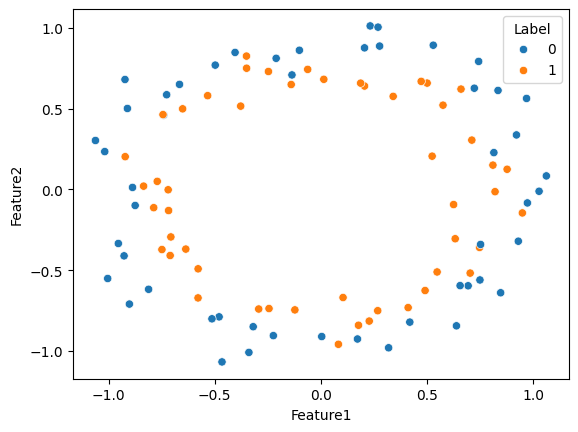

In [6]:
sns.scatterplot(df, x = 'Feature1', y = 'Feature2', hue = 'Label')

In [7]:
# Train test split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, t_test = train_test_split(x, y, test_size = 0.2)

# 1a) `Xavier for Normal Distribution`: 

`np.random.randn(2,2) * sqrt(1 / no_of_inputs to the layer)`

In [8]:
model1 = Sequential()

model1.add(Dense(10, activation = 'tanh', input_dim = 2))
model1.add(Dense(10, activation = 'tanh'))
model1.add(Dense(10, activation = 'tanh'))
model1.add(Dense(10, activation = 'tanh'))
model1.add(Dense(1, activation = 'sigmoid'))

model1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 10)                30        
                                                                 
 dense_1 (Dense)             (None, 10)                110       
                                                                 
 dense_2 (Dense)             (None, 10)                110       
                                                                 
 dense_3 (Dense)             (None, 10)                110       
                                                                 
 dense_4 (Dense)             (None, 1)                 11        
                                                                 
Total params: 371 (1.45 KB)
Trainable params: 371 (1.45 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
model1.get_weights()

[array([[-5.0187111e-04,  4.7460705e-01,  3.1848699e-01, -4.8356116e-02,
          5.0810653e-01, -1.7569435e-01,  6.3534856e-02, -6.5101755e-01,
          6.5944582e-01, -3.1660730e-01],
        [ 5.4982311e-01, -5.6746364e-02, -5.7084769e-01,  5.5317044e-02,
         -4.3851671e-01, -5.1730347e-01, -9.2936158e-02, -4.8563755e-01,
         -6.3178784e-01,  3.6752385e-01]], dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.12432453, -0.06044766, -0.5346102 , -0.24151534,  0.26746434,
          0.24525082, -0.14134634,  0.34919888,  0.3145293 , -0.03155899],
        [ 0.47872686,  0.2635172 , -0.40093783,  0.25034553,  0.14876848,
         -0.07958469, -0.40363523,  0.50712514,  0.03005284,  0.30731696],
        [-0.2865793 ,  0.10495675,  0.02450484, -0.15215725, -0.00862056,
         -0.05415413, -0.4526467 ,  0.08126235,  0.33168542, -0.54673547],
        [-0.04873842,  0.32327586,  0.2837628 , -0.41315776, -0.4914519 ,
         -0.45188826,

In [10]:
initial_weights = model1.get_weights()

In [11]:
# Changing the initial weights. Keepinng biases of all the layers as zero

initial_weights[0] = np.random.randn(2, 10) * np.sqrt(1 / 2)    # sqrt(1/2) bcz it will receive 2 inputs(As it is an input node)
initial_weights[1] = np.zeros(initial_weights[1].shape)         # 1st layer biases

initial_weights[2] = np.random.randn(10, 10) * np.sqrt(1 / 10)  # 2nd layer weights
initial_weights[3] = np.zeros(initial_weights[3].shape)         # 3rd layer's biases

initial_weights[4] = np.random.randn(10, 10) * np.sqrt(1 / 10)  # 3rd layer weights
initial_weights[5] = np.zeros(initial_weights[5].shape)         # 3rd layer's biases

initial_weights[6] = np.random.randn(10, 10) * np.sqrt(1 / 10)  # 4th layer weights
initial_weights[7] = np.zeros(initial_weights[7].shape)         # 4th layer's biases

initial_weights[8] = np.random.randn(10, 1) * np.sqrt(1 / 10)  # 5th layer weights
initial_weights[9] = np.zeros(initial_weights[9].shape)         # th layer's biases

# Changet weights as random and biases as zero(For all layers)

In [12]:
initial_weights

[array([[-0.57823218, -0.16751982, -1.34483705, -0.73165549, -0.07262424,
         -0.07004219,  0.6504304 ,  0.4973217 , -0.38638083, -1.1537504 ],
        [-0.52412538,  0.64595269, -1.10681665,  2.09200231,  0.42014583,
          0.12767402,  0.256647  , -0.73377699, -1.23973404,  0.41120245]]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 array([[ 3.33437285e-01, -1.92671135e-01, -7.79062079e-02,
         -6.23632074e-02, -1.72024580e-01, -2.57568625e-01,
         -6.89929795e-02, -2.28118148e-02,  1.43153862e-01,
         -2.70679800e-01],
        [ 5.55876443e-02,  4.73992515e-01,  9.15714819e-02,
          3.01337010e-01, -2.52972352e-01,  4.63473143e-01,
          1.39284654e-01, -1.57366836e-01,  3.80037885e-01,
          2.61303126e-01],
        [ 3.47339562e-01, -2.59564634e-01, -2.55100219e-02,
         -2.42486468e-01,  3.92101711e-02, -1.78176879e-01,
         -1.03710088e-01, -5.81677281e-01,  1.91289136e-01,
         -5.97984933e-02],
        [ 3.01289940e-01,  1.

In [13]:
# Setting weights

model1.set_weights(initial_weights)

In [14]:
model1.get_weights()[0]

array([[-0.57823217, -0.16751981, -1.3448371 , -0.7316555 , -0.07262424,
        -0.07004219,  0.6504304 ,  0.4973217 , -0.38638082, -1.1537504 ],
       [-0.5241254 ,  0.6459527 , -1.1068166 ,  2.0920024 ,  0.42014584,
         0.12767403,  0.256647  , -0.733777  , -1.239734  ,  0.41120246]],
      dtype=float32)

In [15]:
model1.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [16]:
history1 = model1.fit(x_train, y_train, validation_split = 0.2, epochs = 100)

Epoch 1/100
2/2 [==============================] - 4s 622ms/step - loss: 0.7149 - accuracy: 0.4531 - val_loss: 0.7039 - val_accuracy: 0.3750
Epoch 2/100
2/2 [==============================] - 0s 92ms/step - loss: 0.7111 - accuracy: 0.4531 - val_loss: 0.7014 - val_accuracy: 0.3750
Epoch 3/100
2/2 [==============================] - 0s 89ms/step - loss: 0.7094 - accuracy: 0.4844 - val_loss: 0.6992 - val_accuracy: 0.4375
Epoch 4/100
2/2 [==============================] - 0s 86ms/step - loss: 0.7065 - accuracy: 0.4844 - val_loss: 0.6974 - val_accuracy: 0.4375
Epoch 5/100
2/2 [==============================] - 0s 91ms/step - loss: 0.7048 - accuracy: 0.4844 - val_loss: 0.6957 - val_accuracy: 0.4375
Epoch 6/100
2/2 [==============================] - 0s 89ms/step - loss: 0.7025 - accuracy: 0.4844 - val_loss: 0.6943 - val_accuracy: 0.4375
Epoch 7/100
2/2 [==============================] - 0s 91ms/step - loss: 0.7007 - accuracy: 0.4844 - val_loss: 0.6930 - val_accuracy: 0.5000
Epoch 8/100
2/2 [==

In [17]:
model1.get_weights()

[array([[-0.5967295 , -0.14207274, -1.3276786 , -0.69645554, -0.05103853,
         -0.04514332,  0.6989519 ,  0.53534746, -0.40521258, -1.1024798 ],
        [-0.4976282 ,  0.66606146, -1.0646306 ,  2.065026  ,  0.45344168,
          0.1866632 ,  0.27904293, -0.7132791 , -1.2645285 ,  0.3238083 ]],
       dtype=float32),
 array([ 0.00144726, -0.1093898 , -0.06187041, -0.08629672, -0.04973004,
        -0.03106594, -0.12580732, -0.08574432,  0.13895847, -0.04417349],
       dtype=float32),
 array([[ 3.76153052e-01, -2.44247958e-01, -4.21370193e-02,
         -6.51173368e-02, -1.52224377e-01, -2.35068604e-01,
         -1.00860111e-01,  6.73265848e-03,  9.44426656e-02,
         -2.89651215e-01],
        [-6.23095839e-04,  5.13866544e-01,  4.77995872e-02,
          3.11665535e-01, -3.01925570e-01,  4.31498498e-01,
          1.87622800e-01, -1.97287843e-01,  4.43755001e-01,
          2.75714725e-01],
        [ 4.01224166e-01, -3.13555330e-01,  1.88412461e-02,
         -2.35991716e-01,  7.08726

9600/9600 [==============================] - 29s 3ms/step


Text(0.5, 1.0, 'glorot_normal with tanh')

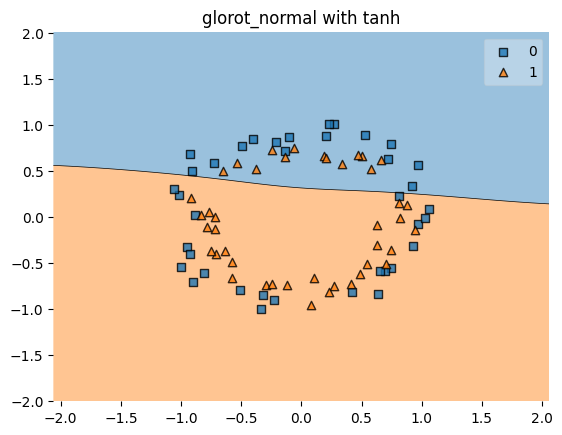

In [18]:
plot_decision_regions(x_train, y_train, clf = model1)
plt.title('glorot_normal with tanh')

# We can see that the model is trying to capture the non-linearity in the data even in 100 epochs.
# If we increase the epochs, it'll learn to classify the data in a more batter way.

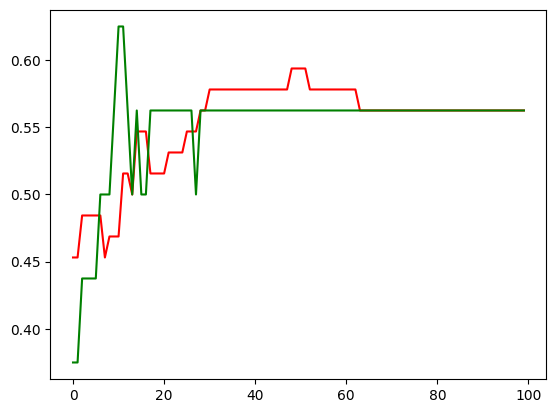

In [19]:
plt.plot(history1.history['accuracy'], color = 'red')
plt.plot(history1.history['val_accuracy'], color = 'green')

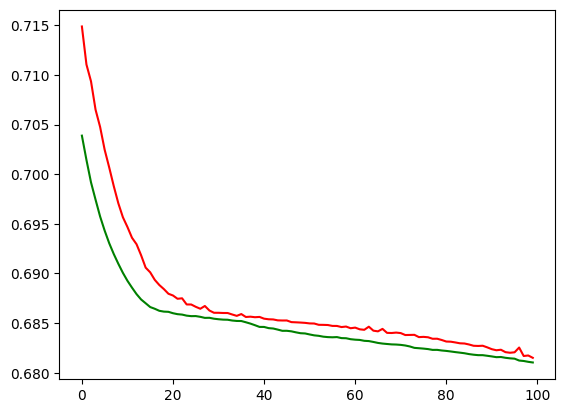

In [20]:
plt.plot(history1.history['loss'], color = 'red')
plt.plot(history1.history['val_loss'], color = 'green')

# `Remember:`A good decision boundry doesn't mean good model. A model with good decision boundry may also have overfitting or underfitting. So always try to plot training and validation accuracy and loss and see whether the model is overfitting or underfitting. If yes, solve the problem.


# 2a) He initialization: Used with `relu` activation function

`Formula:` np.random.randn(shape) * sqrt(2 / no_of_inputs) <br>

`The change is only on sqrt. In Xavier we are multiplying with sqrt of (1/no_of_inputs) and here we are multiplying with sqrt(2/no_of_inputs)`

In [21]:
model2 = Sequential()

model2.add(Dense(10, activation = 'relu', input_dim = 2))
model2.add(Dense(10, activation = 'relu'))
model2.add(Dense(10, activation = 'relu'))
model2.add(Dense(10, activation = 'relu'))
model2.add(Dense(1, activation = 'sigmoid'))

model2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_5 (Dense)             (None, 10)                30        
                                                                 
 dense_6 (Dense)             (None, 10)                110       
                                                                 
 dense_7 (Dense)             (None, 10)                110       
                                                                 
 dense_8 (Dense)             (None, 10)                110       
                                                                 
 dense_9 (Dense)             (None, 1)                 11        
                                                                 
Total params: 371 (1.45 KB)
Trainable params: 371 (1.45 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [22]:
model2.get_weights()

[array([[ 0.308744  , -0.27758503,  0.27753395,  0.46074122, -0.7041713 ,
          0.1334182 , -0.04271972, -0.51177144,  0.45011014,  0.45669717],
        [-0.10879582,  0.08806109,  0.15202773,  0.07667172, -0.08527404,
         -0.6963494 , -0.10128224, -0.61171633,  0.59925956,  0.08424681]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.16715714, -0.0156163 , -0.3984013 , -0.3287629 ,  0.16793048,
          0.46471977, -0.28290576, -0.3686086 ,  0.24923462, -0.15859821],
        [ 0.45942342, -0.35681212,  0.46035254,  0.15779692,  0.299155  ,
          0.46133578,  0.10139263,  0.26867843,  0.17477888,  0.43862867],
        [-0.53572094, -0.16578206,  0.43282264,  0.3596465 , -0.50414836,
          0.44445395,  0.54303396,  0.34398204, -0.22527146,  0.01055461],
        [-0.4021289 ,  0.17340899,  0.28357452,  0.31166863, -0.45255518,
         -0.5321204 , -0.07541922,  0.52349377, -0.5194288 ,  0.34142268],
        [-0.13666

In [23]:
# Note: Initially, model assigns biases as zero for all the layers.

In [24]:
initial_weights = model2.get_weights()

In [25]:
initial_weights[0] = np.random.randn(2, 10) * np.sqrt(2 / 2)    # Weights if 1st layer
initial_weights[2] = np.random.randn(10,10)  * np.sqrt(2 / 10)   # Weights if 2nd layer
initial_weights[4] = np.random.randn(10,10) * np.sqrt(2 / 10)   # Weights if 3rd layer
initial_weights[6] = np.random.randn(10,10) * np.sqrt(2 / 10)   # Weights if 4th layer
initial_weights[8] = np.random.randn(10,1) * np.sqrt(2 / 10)   # Weights if 5th layer


In [26]:
initial_weights

[array([[ 0.4594188 ,  0.99191629,  1.24324036, -1.13097567,  1.80872285,
          0.01326722,  0.50427825,  0.10789413, -2.00335796, -0.49846329],
        [ 1.5798557 , -0.99895675, -0.42771928, -1.28109361, -0.04181509,
          0.32371626,  1.02521234, -0.1826368 , -0.4160229 , -1.44847304]]),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.17754728, -0.02387432,  0.02276112,  0.11393081,  0.34354413,
         -0.62657623, -0.83738353, -0.08136139,  0.69690848,  0.40645669],
        [ 0.0765506 ,  0.3516113 ,  0.31056649,  0.62282259,  0.04657255,
         -0.57779557, -0.01824763, -0.65851573, -0.32557359, -0.00851805],
        [-0.16559616,  0.40824028,  0.32258434, -0.11797725, -0.10214997,
         -0.13498435, -0.3211763 , -0.10544253,  0.17377397,  0.44188615],
        [-0.07634324, -0.06912829,  0.75770631, -0.19997092,  0.1678929 ,
         -0.50399263, -0.43143274,  0.04646815,  0.53969115,  0.07703731],
        [-0.071855  ,  0.56991453, -0.5

In [27]:
model2.set_weights(initial_weights)

In [28]:
model2.get_weights()

[array([[ 0.4594188 ,  0.9919163 ,  1.2432404 , -1.1309757 ,  1.8087229 ,
          0.01326722,  0.50427824,  0.10789413, -2.003358  , -0.49846327],
        [ 1.5798557 , -0.99895674, -0.4277193 , -1.2810936 , -0.04181509,
          0.32371625,  1.0252123 , -0.1826368 , -0.4160229 , -1.4484731 ]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-0.17754728, -0.02387432,  0.02276112,  0.11393081,  0.34354413,
         -0.62657624, -0.8373835 , -0.08136139,  0.6969085 ,  0.40645668],
        [ 0.0765506 ,  0.35161132,  0.31056648,  0.6228226 ,  0.04657255,
         -0.57779557, -0.01824763, -0.65851575, -0.3255736 , -0.00851805],
        [-0.16559616,  0.4082403 ,  0.32258433, -0.11797725, -0.10214996,
         -0.13498434, -0.3211763 , -0.10544253,  0.17377397,  0.44188616],
        [-0.07634324, -0.06912829,  0.7577063 , -0.19997093,  0.1678929 ,
         -0.5039926 , -0.43143275,  0.04646815,  0.53969115,  0.07703731],
        [-0.07185

In [29]:
model2.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [30]:
history2 = model2.fit(x_train, y_train, validation_split = 0.2, epochs = 100)

Epoch 1/100
2/2 [==============================] - 3s 483ms/step - loss: 0.7989 - accuracy: 0.5156 - val_loss: 0.6968 - val_accuracy: 0.5625
Epoch 2/100
2/2 [==============================] - 0s 84ms/step - loss: 0.7888 - accuracy: 0.5156 - val_loss: 0.6935 - val_accuracy: 0.5625
Epoch 3/100
2/2 [==============================] - 0s 83ms/step - loss: 0.7799 - accuracy: 0.5156 - val_loss: 0.6906 - val_accuracy: 0.5625
Epoch 4/100
2/2 [==============================] - 0s 82ms/step - loss: 0.7698 - accuracy: 0.5156 - val_loss: 0.6884 - val_accuracy: 0.5625
Epoch 5/100
2/2 [==============================] - 0s 86ms/step - loss: 0.7637 - accuracy: 0.5000 - val_loss: 0.6868 - val_accuracy: 0.5000
Epoch 6/100
2/2 [==============================] - 0s 85ms/step - loss: 0.7567 - accuracy: 0.5000 - val_loss: 0.6857 - val_accuracy: 0.5625
Epoch 7/100
2/2 [==============================] - 0s 86ms/step - loss: 0.7498 - accuracy: 0.4844 - val_loss: 0.6850 - val_accuracy: 0.5625
Epoch 8/100
2/2 [==

9600/9600 [==============================] - 28s 3ms/step


Text(0.5, 1.0, 'he_normal with relu')

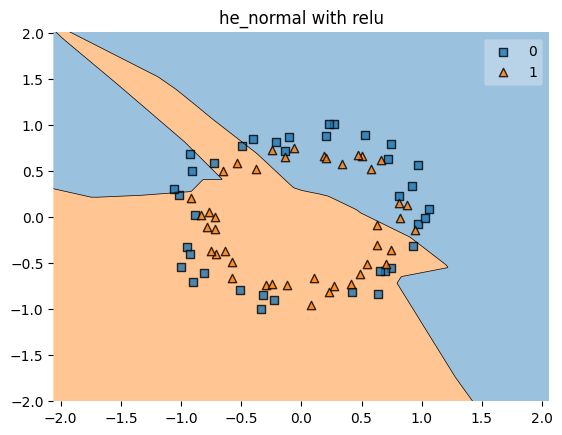

In [31]:
plot_decision_regions(x_train, y_train, clf = model2)
plt.title("he_normal with relu")

# `Xavier Uniform:` Weights are initialized in the range of [-limits, limits]
Formula: limits = sqrt(6 / no_of_inputs + no_of_outputs)

# `He Uniform:`Weights are initialized in the range of [-limits, limits]
Formula: limits = sqrt(6 / no_of_inputs)

# Now, There's a `GOOD NEWS`. 

We don't need to remember these formulae bcz there's a paraeter `kernel_initializer` in add() method where we can pass various weights initializers to it.

In [32]:
model3 = Sequential()

model3.add(Dense(10, activation = 'tanh', input_dim = 2, kernel_initializer = 'glorot_normal'))
model3.add(Dense(10, activation = 'tanh', kernel_initializer = 'glorot_normal'))
model3.add(Dense(10, activation = 'tanh', kernel_initializer = 'glorot_normal'))
model3.add(Dense(10, activation = 'tanh', kernel_initializer = 'glorot_normal'))
model3.add(Dense(1, activation = 'sigmoid', kernel_initializer = 'glorot_normal'))


In [33]:
model3.get_weights()

[array([[ 0.41197985,  0.6045018 , -0.39624056, -0.41649926,  0.34075162,
          0.43011862,  0.04712293,  0.42587095,  0.42378062,  0.0578127 ],
        [ 0.24482438,  0.00103635, -0.17297512, -0.54567903, -0.67139786,
         -0.20861496, -0.13139898,  0.40041888,  0.13267793,  0.26606172]],
       dtype=float32),
 array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([[-1.96154714e-02,  5.11157662e-02,  1.17538087e-01,
          2.62422934e-02,  5.27453482e-01,  1.82011947e-01,
          5.99371254e-01,  4.68818158e-01, -3.02455127e-01,
         -1.18880190e-01],
        [-1.75772563e-01,  2.41400361e-01,  2.58320212e-01,
          6.54170275e-01,  1.44025952e-01,  3.43395695e-02,
          1.15997568e-01, -3.07124078e-01,  5.80000103e-01,
          4.69062813e-02],
        [-3.06035340e-01, -2.88052171e-01, -5.52011728e-01,
         -4.71472830e-01, -5.76490760e-02, -1.78423837e-01,
         -1.14659391e-01,  2.20943213e-01,  4.14239973e-01,
         -4.9350136

In [34]:
model3.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [35]:
history3 = model3.fit(x_train, y_train, validation_split = 0.2, epochs = 100)

Epoch 1/100
2/2 [==============================] - 3s 493ms/step - loss: 0.6981 - accuracy: 0.4688 - val_loss: 0.6967 - val_accuracy: 0.5625
Epoch 2/100
2/2 [==============================] - 0s 84ms/step - loss: 0.6967 - accuracy: 0.5000 - val_loss: 0.6949 - val_accuracy: 0.5625
Epoch 3/100
2/2 [==============================] - 0s 85ms/step - loss: 0.6952 - accuracy: 0.4844 - val_loss: 0.6934 - val_accuracy: 0.4375
Epoch 4/100
2/2 [==============================] - 0s 87ms/step - loss: 0.6939 - accuracy: 0.5000 - val_loss: 0.6922 - val_accuracy: 0.5625
Epoch 5/100
2/2 [==============================] - 0s 84ms/step - loss: 0.6930 - accuracy: 0.5000 - val_loss: 0.6911 - val_accuracy: 0.5625
Epoch 6/100
2/2 [==============================] - 0s 82ms/step - loss: 0.6921 - accuracy: 0.4844 - val_loss: 0.6899 - val_accuracy: 0.5625
Epoch 7/100
2/2 [==============================] - 0s 85ms/step - loss: 0.6908 - accuracy: 0.5156 - val_loss: 0.6891 - val_accuracy: 0.5625
Epoch 8/100
2/2 [==

9600/9600 [==============================] - 27s 3ms/step


Text(0.5, 1.0, 'Glorot_normal with tanh')

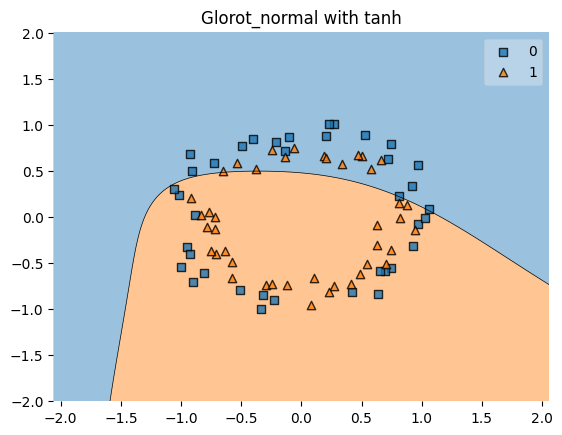

In [36]:
plot_decision_regions(x_train, y_train, clf = model3)
plt.title('Glorot_normal with tanh')

# We can see, we are getting the same result as we were getting while we used formula.

# Glorot uniform with tanh

In [37]:
model4 = Sequential()

model4.add(Dense(10, activation = 'tanh', input_dim = 2, kernel_initializer = 'glorot_uniform'))
model4.add(Dense(10, activation = 'tanh', kernel_initializer = 'glorot_uniform'))
model4.add(Dense(10, activation = 'tanh', kernel_initializer = 'glorot_uniform'))
model4.add(Dense(10, activation = 'tanh', kernel_initializer = 'glorot_uniform'))
model4.add(Dense(1, activation = 'sigmoid', kernel_initializer = 'glorot_uniform'))

model4.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_15 (Dense)            (None, 10)                30        
                                                                 
 dense_16 (Dense)            (None, 10)                110       
                                                                 
 dense_17 (Dense)            (None, 10)                110       
                                                                 
 dense_18 (Dense)            (None, 10)                110       
                                                                 
 dense_19 (Dense)            (None, 1)                 11        
                                                                 
Total params: 371 (1.45 KB)
Trainable params: 371 (1.45 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [38]:
model4.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [39]:
history4 = model4.fit(x_train, y_train, validation_split = 0.2, epochs = 100)

Epoch 1/100
2/2 [==============================] - 3s 470ms/step - loss: 0.7067 - accuracy: 0.5156 - val_loss: 0.7038 - val_accuracy: 0.5000
Epoch 2/100
2/2 [==============================] - 0s 84ms/step - loss: 0.7041 - accuracy: 0.5000 - val_loss: 0.7018 - val_accuracy: 0.5000
Epoch 3/100
2/2 [==============================] - 0s 85ms/step - loss: 0.7010 - accuracy: 0.5156 - val_loss: 0.7002 - val_accuracy: 0.5000
Epoch 4/100
2/2 [==============================] - 0s 88ms/step - loss: 0.6994 - accuracy: 0.5156 - val_loss: 0.6985 - val_accuracy: 0.5000
Epoch 5/100
2/2 [==============================] - 0s 83ms/step - loss: 0.6974 - accuracy: 0.5156 - val_loss: 0.6971 - val_accuracy: 0.5000
Epoch 6/100
2/2 [==============================] - 0s 86ms/step - loss: 0.6965 - accuracy: 0.5156 - val_loss: 0.6956 - val_accuracy: 0.5000
Epoch 7/100
2/2 [==============================] - 0s 84ms/step - loss: 0.6945 - accuracy: 0.5156 - val_loss: 0.6945 - val_accuracy: 0.5000
Epoch 8/100
2/2 [==

9600/9600 [==============================] - 28s 3ms/step


Text(0.5, 1.0, 'Glorot_uniform with tanh')

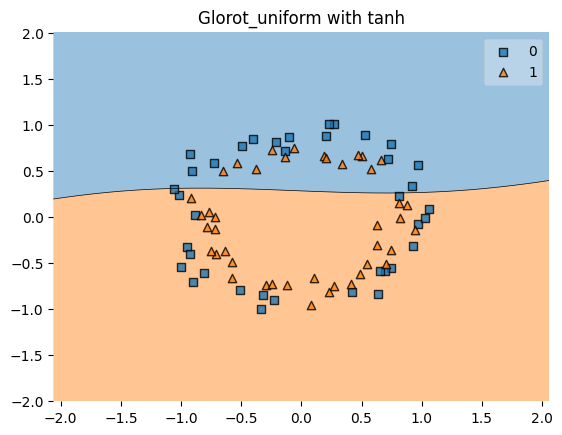

In [40]:
plot_decision_regions(x_train, y_train, clf = model4)
plt.title('Glorot_uniform with tanh')

`We're getting almost same result in Glorot_normal and uniform`

# He_uniform with relu

In [41]:
model5 = Sequential()

model5.add(Dense(10, activation = 'relu', input_dim = 2, kernel_initializer = 'he_uniform'))
model5.add(Dense(10, activation = 'relu', kernel_initializer = 'he_uniform'))
model5.add(Dense(10, activation = 'relu', kernel_initializer = 'he_uniform'))
model5.add(Dense(10, activation = 'relu', kernel_initializer = 'he_uniform'))
model5.add(Dense(1, activation = 'sigmoid', kernel_initializer = 'he_uniform'))

model5.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_20 (Dense)            (None, 10)                30        
                                                                 
 dense_21 (Dense)            (None, 10)                110       
                                                                 
 dense_22 (Dense)            (None, 10)                110       
                                                                 
 dense_23 (Dense)            (None, 10)                110       
                                                                 
 dense_24 (Dense)            (None, 1)                 11        
                                                                 
Total params: 371 (1.45 KB)
Trainable params: 371 (1.45 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [42]:
model4.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [43]:
history4 = model4.fit(x_train, y_train, validation_split = 0.2, epochs = 500)

Epoch 1/500
2/2 [==============================] - 3s 486ms/step - loss: 0.6838 - accuracy: 0.5625 - val_loss: 0.6817 - val_accuracy: 0.5625
Epoch 2/500
2/2 [==============================] - 0s 83ms/step - loss: 0.6831 - accuracy: 0.5781 - val_loss: 0.6815 - val_accuracy: 0.5625
Epoch 3/500
2/2 [==============================] - 0s 92ms/step - loss: 0.6832 - accuracy: 0.5781 - val_loss: 0.6816 - val_accuracy: 0.5625
Epoch 4/500
2/2 [==============================] - 0s 82ms/step - loss: 0.6831 - accuracy: 0.5781 - val_loss: 0.6816 - val_accuracy: 0.5625
Epoch 5/500
2/2 [==============================] - 0s 84ms/step - loss: 0.6828 - accuracy: 0.5625 - val_loss: 0.6815 - val_accuracy: 0.5625
Epoch 6/500
2/2 [==============================] - 0s 87ms/step - loss: 0.6828 - accuracy: 0.5625 - val_loss: 0.6814 - val_accuracy: 0.5625
Epoch 7/500
2/2 [==============================] - 0s 86ms/step - loss: 0.6827 - accuracy: 0.5625 - val_loss: 0.6814 - val_accuracy: 0.5625
Epoch 8/500
2/2 [==

9600/9600 [==============================] - 27s 3ms/step


Text(0.5, 1.0, 'he_uniform with tanh')

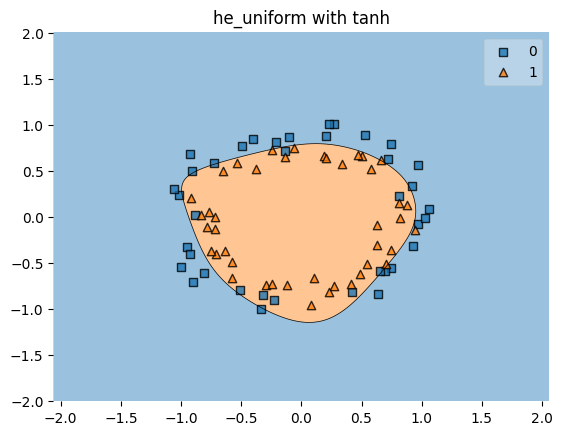

In [44]:
plot_decision_regions(x_train, y_train, clf = model4)
plt.title('he_uniform with tanh')

In [45]:
# We can see, the model is trying to capture the non-linearity and if we increase the epochs, 
# it will give more better results

# Default initializer is `glorot_uniform`.

# Conclusion: All the four initializers are working well and trying to capture the non-linearity present in the data. If we increase the no_of epochs, all four will give good results.

# In the end, remember, just by looking at the decision boundries, we should never decide whether model is working well or not. We should always plot training and val accuracy and loss and find if the model is overfitting or underfitting,  if yes, solve that problem.